In [42]:
# import the libraries
import numpy as np 
import pandas as pd
from pandas_datareader import data as wb
import matplotlib.pyplot as plt
%matplotlib inline
import yfinance as yf

In [43]:
assets = ['HBCYF','D05.SI']
# Download 'Close' prices for all tickers at once
asset = yf.download(assets, start='2020-01-01', end='2026-01-01')['Close']

C:\Users\USER\AppData\Local\Temp\ipykernel_32316\3421297885.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  asset = yf.download(assets, start='2020-01-01', end='2026-01-01')['Close']
[*********************100%***********************]  2 of 2 completed


In [44]:
asset.tail()

Ticker,D05.SI,HBCYF
Date,,
2025-12-24,54.160694,15.378042
2025-12-26,54.093357,15.524035
2025-12-29,54.064495,15.193115
2025-12-30,54.353096,15.504570
2025-12-31,54.218418,15.280712


<Axes: xlabel='Date'>

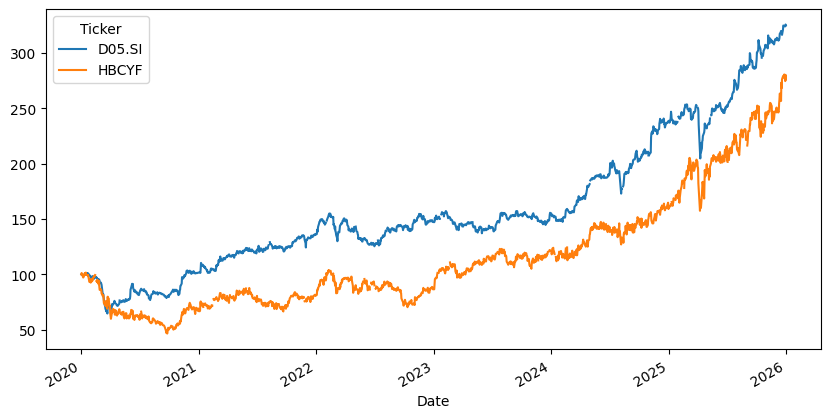

In [45]:
(asset/ asset.iloc[0] *100).plot(figsize=(10,5))

In [46]:
log_returns = np.log(asset/asset.shift(1))

In [47]:
log_returns.mean() *250

Ticker
D05.SI    0.173838
HBCYF     0.151188
dtype: float64

In [48]:
log_returns.cov()*250

Ticker,D05.SI,HBCYF
Ticker,,
D05.SI,0.038829,0.020712
HBCYF,0.020712,0.159544


In [49]:
log_returns.corr()

Ticker,D05.SI,HBCYF
Ticker,,
D05.SI,1.000000,0.256636
HBCYF,0.256636,1.000000


In [50]:
num_assets = len(assets)

In [51]:
num_assets

2

In [52]:
arr = np.random.random(2)
arr

array([0.18991423, 0.61073746])

In [53]:
arr[0]+arr[1]

np.float64(0.8006516879000543)

In [54]:
weights = np.random.random(num_assets)
weights /= np.sum(weights)
weights

array([0.50598495, 0.49401505])

In [55]:
weights[0]+weights[1]

np.float64(1.0)

In [56]:
#expected portfolio return
np.sum(weights * log_returns.mean())*250

np.float64(0.16264871364759648)

In [57]:
#expected portfolio variance
np.dot(weights.T, np.dot(log_returns.cov() *250, weights))

np.float64(0.059232151015728055)

In [58]:
# expected portfolio volatility
np.sqrt(np.dot(weights.T,np.dot(log_returns.cov()*250,weights)))

np.float64(0.2433765621741914)

In [64]:
pfolio_returns = []
pfolio_volatilities = []
for x in range(1000):
    weights = np.random.random(num_assets)
    weights /= np.sum(weights)
    pfolio_returns.append(np.sum(weights * log_returns.mean())*250)
    pfolio_volatilities.append(np.sqrt(np.dot(weights.T,np.dot(log_returns.cov() *250, weights))))
pfolio_returns,pfolio_volatilities

([np.float64(0.16536603783317183),
  np.float64(0.16502803879503794),
  np.float64(0.16670018596468217),
  np.float64(0.15702934313307934),
  np.float64(0.1624378813812935),
  np.float64(0.16039657285398012),
  np.float64(0.15676563840363483),
  np.float64(0.1632466187219804),
  np.float64(0.17246626995528216),
  np.float64(0.16722059221497698),
  np.float64(0.16483198550387862),
  np.float64(0.16036521239139698),
  np.float64(0.15774280446136563),
  np.float64(0.1607022859788906),
  np.float64(0.15941564011622966),
  np.float64(0.16074894416482727),
  np.float64(0.157453947281782),
  np.float64(0.1601040427891735),
  np.float64(0.16109126702103005),
  np.float64(0.165775223365605),
  np.float64(0.15716838897243657),
  np.float64(0.15932369537163513),
  np.float64(0.16156025343302022),
  np.float64(0.16908523431946587),
  np.float64(0.16017006982716137),
  np.float64(0.1571366961933582),
  np.float64(0.15172933465269436),
  np.float64(0.15609797563969297),
  np.float64(0.15257374392877

In [67]:
pfolio_returns = []
pfolio_volatilities = []
for x in range(1000):
    weights = np.random.random(num_assets)
    weights /= np.sum(weights)
    pfolio_returns.append(np.sum(weights * log_returns.mean())*250)
    pfolio_volatilities.append(np.sqrt(np.dot(weights.T,np.dot(log_returns.cov() *250, weights))))
pfolio_returns = np.array(pfolio_returns)
pfolio_volatilities = np.array(pfolio_volatilities)
pfolio_returns, pfolio_volatilities

(array([0.16498616, 0.1713802 , 0.16055241, 0.16286081, 0.16313954,
        0.16562556, 0.16084481, 0.16698862, 0.15676011, 0.15375635,
        0.15172925, 0.15908382, 0.15227904, 0.16329287, 0.1637498 ,
        0.16141267, 0.16303304, 0.16133103, 0.15840727, 0.16675624,
        0.16180372, 0.16635764, 0.15680406, 0.15867303, 0.15800602,
        0.1707157 , 0.1564463 , 0.17031162, 0.15743844, 0.16302055,
        0.1634235 , 0.16684853, 0.15772112, 0.1545997 , 0.15916116,
        0.15755463, 0.16371194, 0.1620444 , 0.16596582, 0.16478272,
        0.16172854, 0.16027675, 0.17122142, 0.15597645, 0.16270098,
        0.16275731, 0.15994433, 0.16229852, 0.16325439, 0.16092356,
        0.15181856, 0.16283782, 0.16646283, 0.16246107, 0.16040976,
        0.15207847, 0.16109707, 0.16199999, 0.16611672, 0.16106432,
        0.1674117 , 0.1624864 , 0.16304754, 0.1626606 , 0.16281833,
        0.16139308, 0.15413227, 0.1634328 , 0.16267355, 0.15948486,
        0.15311391, 0.16203721, 0.16293326, 0.17

In [68]:
portfolios = pd.DataFrame({'Return':pfolio_returns, 'Volatility':pfolio_volatilities})

In [69]:
portfolios.head()

,Return,Volatility
0,0.164986,0.220544
1,0.171380,0.191690
2,0.160552,0.267536
3,0.162861,0.241108
4,0.163140,0.238182


In [70]:
portfolios.tail()

,Return,Volatility
995,0.171072,0.191689
996,0.167716,0.201251
997,0.162710,0.242712
998,0.156296,0.323895
999,0.166349,0.209778


Text(0, 0.5, 'Expected Return')

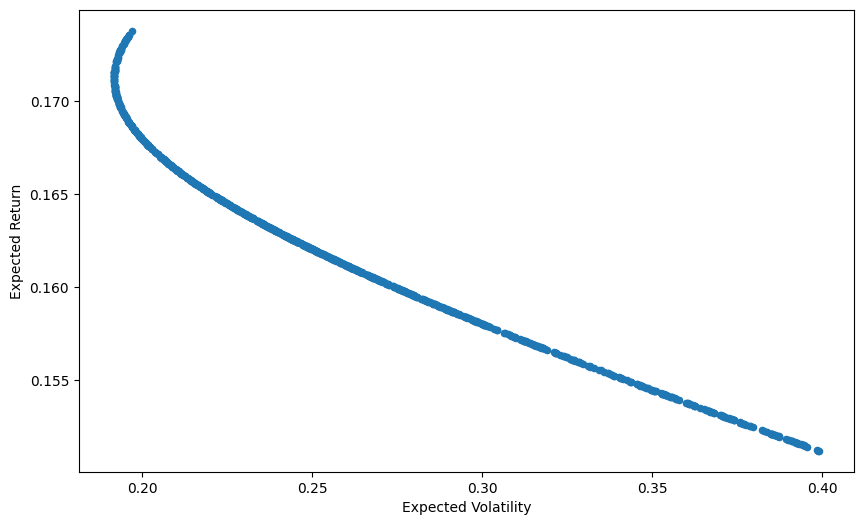

In [72]:
portfolios.plot(x='Volatility', y='Return', kind ='scatter',figsize=(10,6));
plt.xlabel('Expected Volatility')
plt.ylabel('Expected Return')